# Project Proposal

### Vrije Universiteit Amsterdam
### Minor in Data Science: Introduction to Data Science
#### Group 23 Members
* Bonolo Phoi
* Arianna Kuyasha Quispe Digiusto
* Gabrielle Barthelmy


## Introduction and Business Problem

Human Immunodeficiency Virus (HIV) affects millions of people worldwide, and Hepatitis B Virus (HBV) is one of the most common co-infections among people living with HIV due to their shared modes of transmission. People living with HIV are also more likely to develop chronic hepatitis, and HIV/HBV co-infection is particularly prevalent in sub-Saharan Africa (Chiesa et al., 2020; Dagnaw et al., 2025). This co-infection can complicate HIV treatment by increasing the risk of liver damage and other complications. Therefore, this project uses demographic, clinical, and viral exposure information from HIV-positive patients in Northern Uganda to identify factors associated with HBV co-infection. Specifically, we will use HBsAg status as the outcome variable in a multivariable regression model to determine which patient characteristics are associated with HBV positivity. Identifying these factors could help support earlier HBV screening and inform treatment decisions for people living with HIV, potentially reducing complications associated with undiagnosed co-infection.

In [25]:
import pandas as pd
import numpy as np
import math  
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score

## Understanding the Data

This dataset contains information from 950 people living with HIV in Northern Uganda and was obtained from an academic study examining HIV and HBV coinfection. The dataset contains 26 variables covering patient demographics, HBV exposure history, HIV treatment, disease progression, and clinical laboratory measurements. The data will be used to examine the relationship between these patient characteristics and HBV infection. HBsAg status will serve as the outcome variable in our model, while relevant demographic, clinical, and exposure characteristics will be considered as predictors. The dataset provides patient-level information that allows us to examine multiple factors simultaneously rather than looking at HBV infection based on a single characteristic.



In [26]:
df = pd.read_csv('data/hivdata.csv')  
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])
df.info()

Number of observations: 950
Number of variables: 26
<class 'pandas.DataFrame'>
RangeIndex: 950 entries, 0 to 949
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PATIENT'S ID               950 non-null    int64  
 1   AGE                        949 non-null    float64
 2   GENDER                     950 non-null    str    
 3   SEX WORKER                 950 non-null    str    
 4   BLOOD TRANSFUSION          950 non-null    str    
 5   HBsAg                      950 non-null    str    
 6   REFUGEE CAMP               950 non-null    str    
 7   USE OF INJECTION DRUGS     950 non-null    str    
 8   MOTHER WITH HBV            950 non-null    str    
 9   TRIBE                      950 non-null    str    
 10  EDUCATION                  950 non-null    str    
 11  HBV IN THE COMPOUND        950 non-null    str    
 12  CIRCUMCISION               950 non-null    str    
 13  THERAPY (

## First 15 Entries of the Data

In [27]:
df.head(15)

,PATIENT'S ID,AGE,GENDER,SEX WORKER,BLOOD TRANSFUSION,HBsAg,REFUGEE CAMP,USE OF INJECTION DRUGS,MOTHER WITH HBV,TRIBE,...,Months in therapy,WHO stage at ART start,WHO stage actual,ALT,AST,CD4-DIAGNOSIS,CD4-START THERAPY,MORE RECENT CD4,START THERAPY,ACTUAL THERAPY
0,1,65.9,F,no,no,no,yes,no,don't know / no data,Acholi,...,135.0,3,2,NaN,NaN,70.0,70.0,507.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
1,2,30.4,F,no,no,no,yes,no,no,Acholi,...,65.0,no data,1,NaN,NaN,343.0,343.0,796.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
2,3,42.0,m,no,yes,no,no,no,no,Acholi,...,78.0,4,no data,NaN,NaN,4.0,4.0,198.0,3TC-AZT-(NVP/EFV/LPVr/ATVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
3,4,58.3,F,no,no,no,yes,no,no,Acholi,...,102.0,3,3,NaN,NaN,113.0,148.0,386.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
4,5,42.4,m,no,no,no,yes,no,no,Acholi,...,28.0,3,2,NaN,NaN,377.0,377.0,578.0,3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr),3
5,6,45.3,F,no,no,no,no,no,no,Acholi,...,115.0,2,2,NaN,NaN,78.0,78.0,344.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
6,7,47.3,F,no,no,no,no,no,no,Acholi,...,94.0,3,2,NaN,NaN,14.0,14.0,1073.0,FTC-TDF-(NVP/EFV/LPVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
7,8,46.3,F,no,no,no,yes,no,no,Acholi,...,80.0,no data,1,NaN,NaN,265.0,265.0,571.0,3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr),3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr)
8,9,43.6,F,no,no,no,no,no,no,Acholi,...,8.0,no data,no data,NaN,NaN,645.0,421.0,761.0,3TC-TDF-(NVP/EFV/AZT/LPVr/ATVr),no data
9,10,42.7,F,no,no,no,no,no,no,Acholi,...,80.0,4,no data,NaN,NaN,55.0,55.0,496.0,3TC-AZT-(NVP/EFV/LPVr/ATVr),3TC-AZT-(NVP/EFV/LPVr/ATVr)


## Data Limitations

The dataset contains missing values, including 169 missing observations for CD4-Diagnosis, 61 for ALT, and 63 for AST. Categorical variables have not yet been encoded into dummy variables and will require further preprocessing. The dataset focuses on patients from Northern Uganda, which may limit how well the results generalize to other populations. Some demographic and behavioral information is self-reported, which may introduce reporting error.

In [28]:
miss_values = df.isnull().sum()

miss_values[miss_values > 0]

AGE                    1
Months in therapy      3
ALT                   61
AST                   63
CD4-DIAGNOSIS        169
CD4-START THERAPY     44
MORE RECENT CD4       47
dtype: int64

## Original Article and Dataset 
- https://pmc.ncbi.nlm.nih.gov/articles/instance/7673526/bin/pone.0242278.s001.xlsx 
- [Hepatitis B and HIV coinfection in Northern Uganda: Is a decline in HBV prevalence on the horizon?](https://pmc.ncbi.nlm.nih.gov/articles/PMC7673526/)

Binary Data Preparation 
This section, prepares the binary outcome and predictor variables for binary classification. Thus encoding the HBsAg outcome variable as well as the predictor variables into a binary variables (0= negative/no, 1= positive/yes). It is to be observed that only 75 of 950 patients (7.9%) tested positive for HBsAg.

# Part 2 

### Cleaning our Data

#### Categorical
These are the selected variables that we have chosen. Majority of the columns of the dataset are categorical so we will need to create dummy variables after

In [29]:
cat_cols = ['GENDER', 'SEX WORKER', 'BLOOD TRANSFUSION','REFUGEE CAMP', 'USE OF INJECTION DRUGS','MOTHER WITH HBV', 'TRIBE', 'EDUCATION','HBV IN THE COMPOUND', 'THERAPY (YES/NO)','MARITAL STATUS', 'THERAPEUTIC SCARIFICATION']

#### Numerical

In [30]:
num_cols = ['AGE', 'WHO stage at ART start', 'ALT', 'AST', 'CD4-DIAGNOSIS', 'CD4-START THERAPY']

### Creating Cleaned Copy of Data

Citation: OpenAI for the numeric variable cleaning

In [31]:
cl_df = df[cat_cols + num_cols + ['HBsAg']].copy()
# to ensure all the text is consistent 
for col in cat_cols + ['HBsAg']:
    cl_df[col] = cl_df[col].str.strip().str.lower()

# to ensure numbers are consistent
for col in num_cols:
    cl_df[col] = pd.to_numeric(cl_df[col], errors='coerce')

# encoding the HBsAg
cl_df['HBsAg'] = cl_df['HBsAg'].map({'no': 0, 'yes': 1})


print(cl_df.isnull().sum())

GENDER                         0
SEX WORKER                     0
BLOOD TRANSFUSION              0
REFUGEE CAMP                   0
USE OF INJECTION DRUGS         0
MOTHER WITH HBV                0
TRIBE                          0
EDUCATION                      0
HBV IN THE COMPOUND            0
THERAPY (YES/NO)               0
MARITAL STATUS                 0
THERAPEUTIC SCARIFICATION      0
AGE                            1
WHO stage at ART start        73
ALT                           61
AST                           63
CD4-DIAGNOSIS                169
CD4-START THERAPY             44
HBsAg                          0
dtype: int64


### Dropping Data

We seem to have a lot of missing data from patients for multiple categories. Because We cannot run the regression with this much missing data, we're going to drop patients who have missing data in the predictors we have chosen.

After That we will use the get dummies function to turn the categorical variables into ones that can be represented with a 0 or 1. 

In [43]:
cl_df= cl_df.dropna().copy()
#predictors
enc= pd.get_dummies(cl_df[cat_cols + num_cols],columns=cat_cols, drop_first=True, dtype=int)
#target 
y= cl_df['HBsAg']

enc.head(12)

,AGE,WHO stage at ART start,ALT,AST,CD4-DIAGNOSIS,CD4-START THERAPY,GENDER_m,SEX WORKER_yes,BLOOD TRANSFUSION_yes,REFUGEE CAMP_yes,...,EDUCATION_no data,EDUCATION_no formal education,EDUCATION_qualification afther senior six,HBV IN THE COMPOUND_2-yes,HBV IN THE COMPOUND_3-don't know / no data,MARITAL STATUS_married/cohabiting,MARITAL STATUS_no data,MARITAL STATUS_single,MARITAL STATUS_widow/widowed,THERAPEUTIC SCARIFICATION_yes
39,47.2,3.0,35.0,29.0,7.0,7.0,1,0,0,1,...,0,1,0,0,0,1,0,0,0,0
43,37.3,3.0,17.0,19.0,195.0,195.0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
44,53.5,1.0,41.0,32.0,377.0,399.0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
46,36.7,1.0,11.0,20.0,160.0,160.0,0,0,1,1,...,0,1,0,1,0,0,0,0,1,0
47,42.5,1.0,38.0,32.0,1043.0,375.0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
48,29.2,1.0,20.0,29.0,1228.0,845.0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
49,26.6,3.0,46.0,40.0,5.0,5.0,1,0,0,1,...,0,1,0,0,0,0,0,0,0,0
50,38.7,4.0,14.0,19.0,385.0,204.0,0,0,0,1,...,0,1,0,0,1,1,0,0,0,0
51,59.6,1.0,65.0,108.0,784.0,156.0,1,0,0,1,...,0,0,1,0,0,0,0,0,1,0
52,52.4,2.0,25.0,28.0,119.0,119.0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


### Observations

#### HBsAg pos vs neg

#### Visualization of HBsAg Positive and Negative Cases amongst our original sample size
Citation: Open AI for chart code


When looking at the chart here we see that the dataset has way more negative cases than positive cases. This could could a problem for modeling because this suggests an imablance in our data.

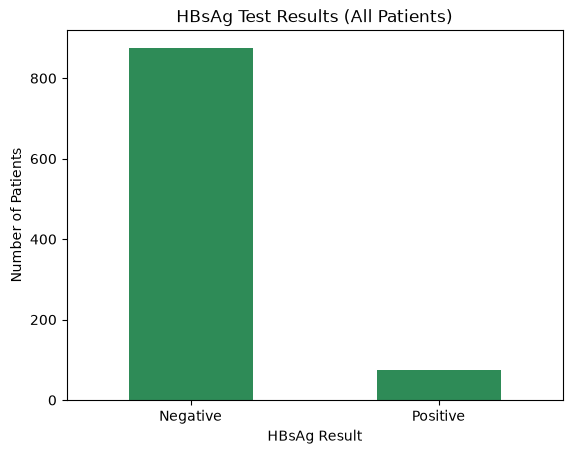

In [33]:
res = df['HBsAg'].astype(str).str.strip().str.lower().map({'no': 'Negative', 'yes': 'Positive'})
res.value_counts().plot(kind='bar', color='seagreen')
plt.title('HBsAg Test Results (All Patients)')
plt.xlabel('HBsAg Result')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.show()

## Visualization of the prevalence amongst different subgroups of the demographic and exposure characteristics
Citation: Open AI for chart code

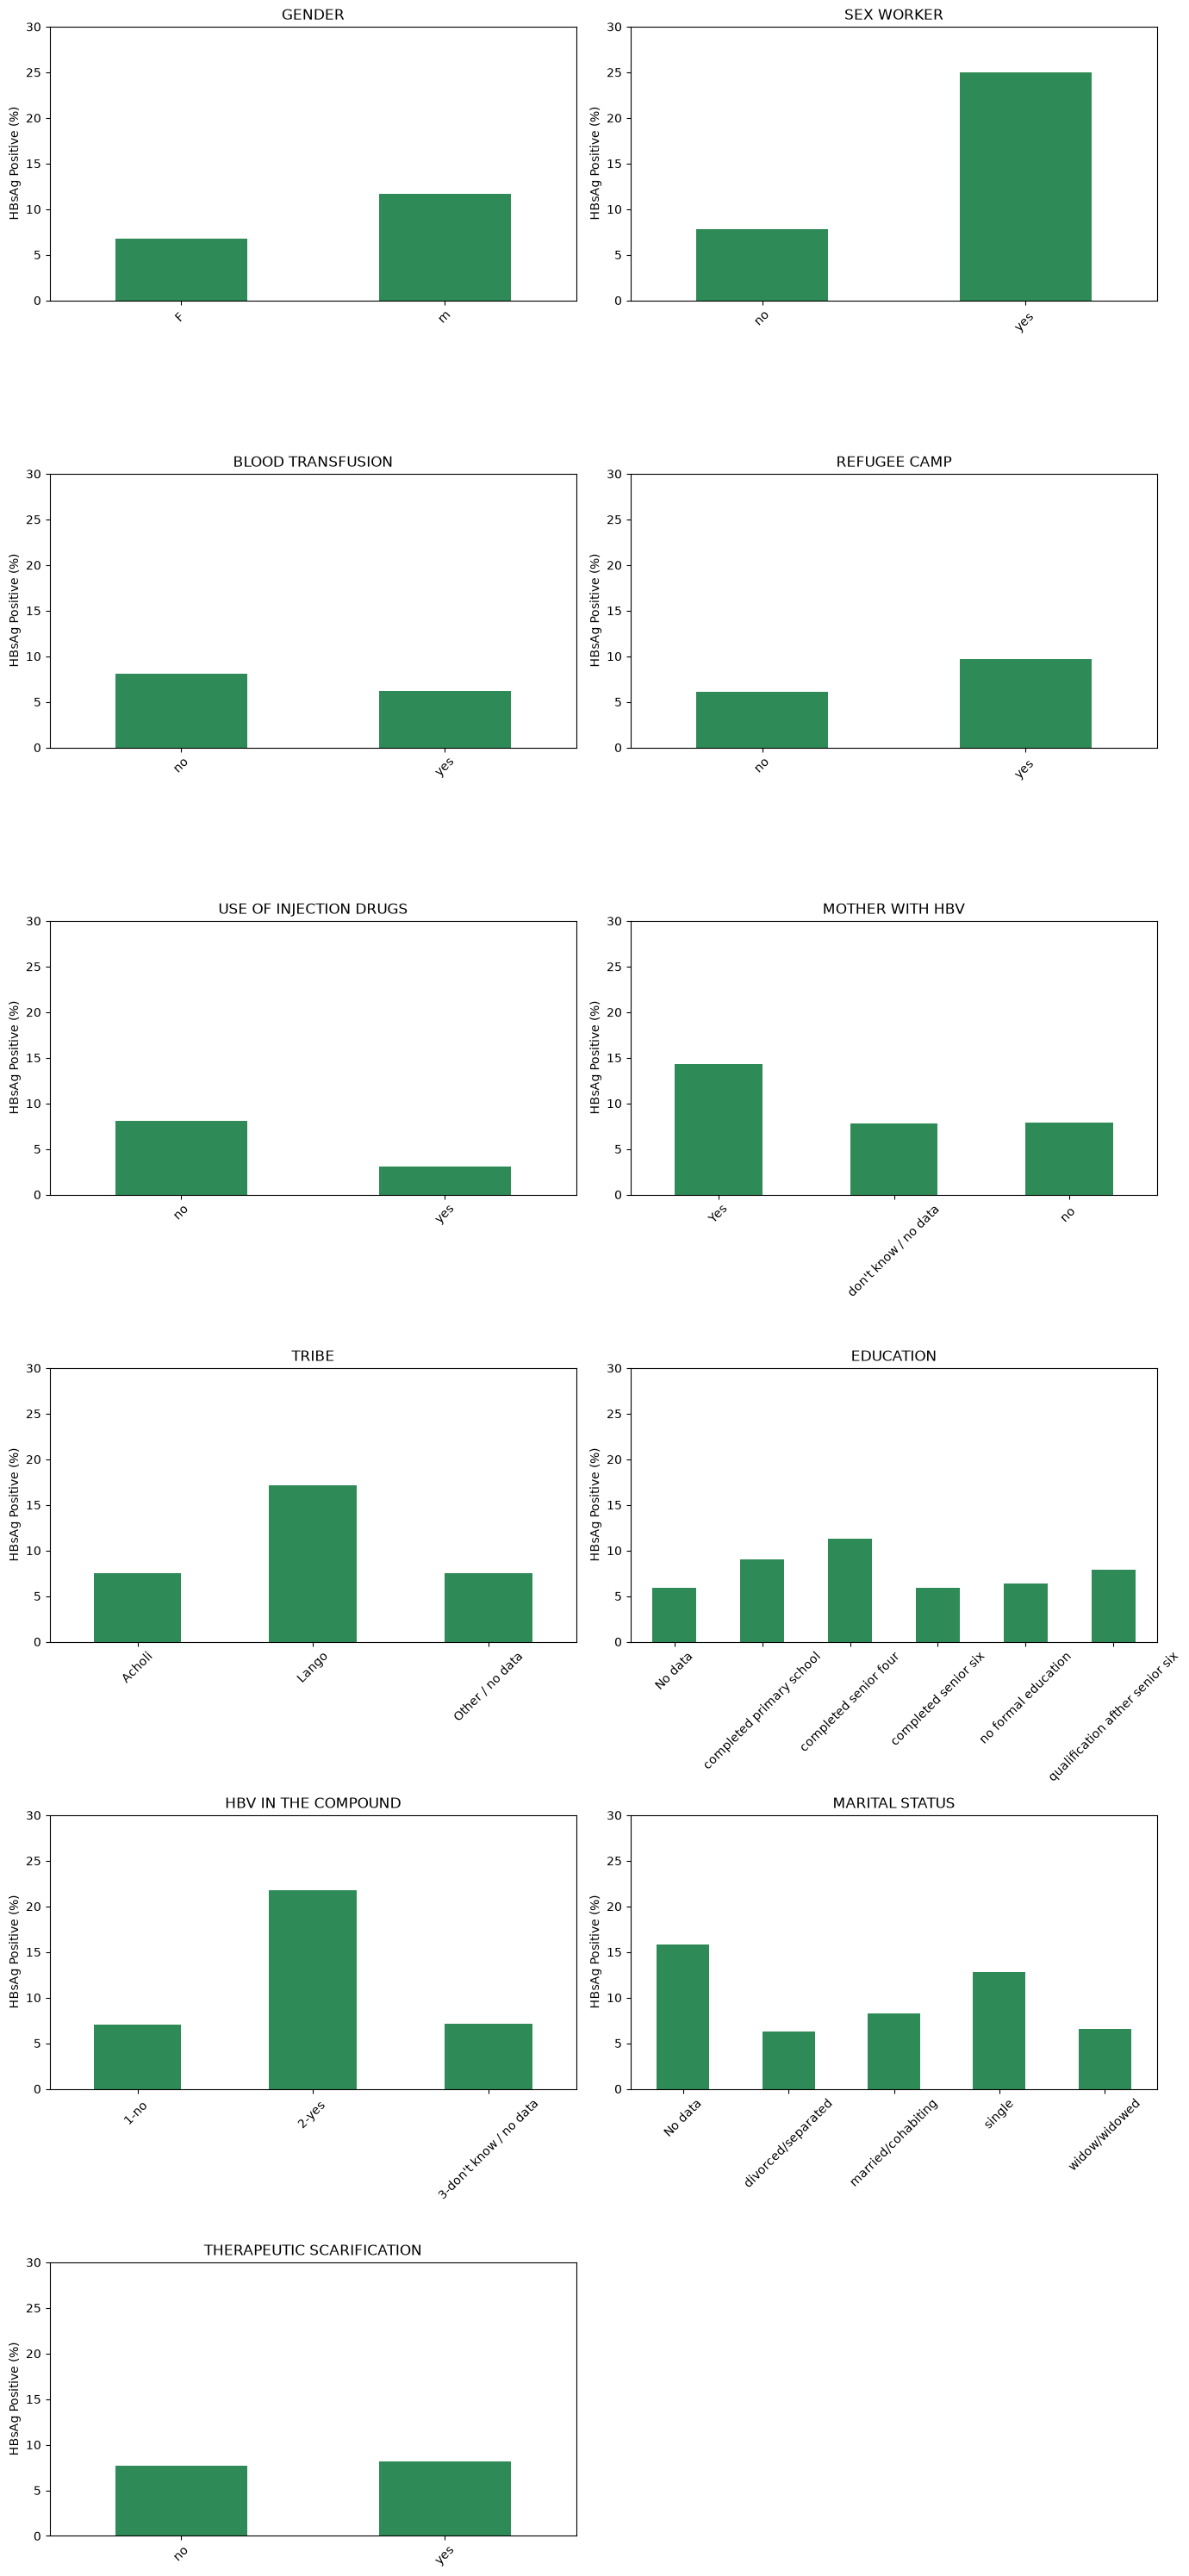

In [42]:
df["HBV_positive"]= df['HBsAg'].astype(str).str.strip().str.lower().map({'no': 0, 'yes': 1})
Variables= ['GENDER', 'SEX WORKER', 'BLOOD TRANSFUSION', 
                        'REFUGEE CAMP','USE OF INJECTION DRUGS',
                       'MOTHER WITH HBV', 'TRIBE', 'EDUCATION', 
                       'HBV IN THE COMPOUND', 
                       'MARITAL STATUS', 
                       'THERAPEUTIC SCARIFICATION']
nrows= math.ceil(len(Variables)/2)
fig,axes = plt.subplots(nrows,2, figsize= (14, 5* nrows), squeeze = False)
axes = axes.flatten()
for i, variable in enumerate(Variables): 
    prevalence = (df.groupby(variable)["HBV_positive"].mean()*100)
    prevalence.plot( kind='bar', color='seagreen', ax= axes[i])
    axes[i].set_title(variable)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('HBsAg Positive (%)')
    axes[i].set_ylim(0,30)
    axes[i].tick_params(axis="x", labelrotation=45)
for ax in axes[len(Variables):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

As shown above,  HBV/HIV co-infection varied across the demographic and exposure subgroups. Higher prevalence was seen among male participants, patients from the Lango tribe, those who have lived in refugee camps and participants who have reported HBV in the compound. Although prevalance amongst sex workers is shown to be higher, these estimates are based on a small subgroup making the results less reliable. These finding suggest potential associations of the subgroup which require further analysis to assess their stastistical significance.  

## Modeling

Since this is a classification problem we will be running a logistic regression where our test and train will be 20 % and 80% respectively.

In [44]:
X_train, X_test, y_train, y_test = train_test_split(enc, y, test_size=0.2, random_state=42, stratify=y)
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [45]:
prob = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, prob)
print("ROC-AUC:", auc)

ROC-AUC: 0.6836077308518254


### Visualization for ROC Curve for Model 1
Citation: Open AI for chart code

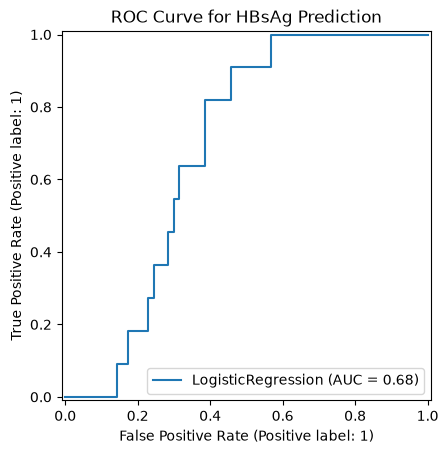

In [46]:
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.title("ROC Curve for HBsAg Prediction")
plt.show()

#### Evaluation of the Model

In [47]:
print(round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))
print(confusion_matrix(y_test, pred))

0.913
              precision    recall  f1-score   support

           0       0.92      0.99      0.95       127
           1       0.00      0.00      0.00        11

    accuracy                           0.91       138
   macro avg       0.46      0.50      0.48       138
weighted avg       0.85      0.91      0.88       138

[[126   1]
 [ 11   0]]


#### Visualization of the Confusion Matrix for our Model
Citation: Open AI for Chart Code

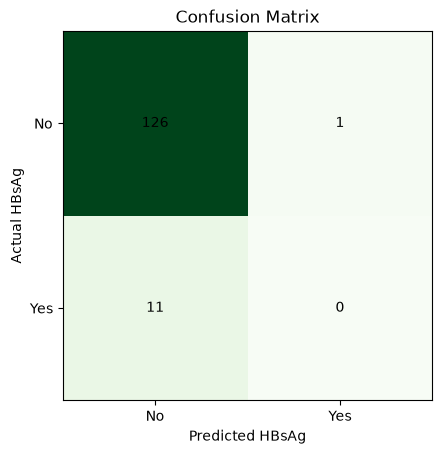

In [48]:
cm = confusion_matrix(y_test, pred)
plt.imshow(cm, cmap='Greens')
plt.title('Confusion Matrix')
plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])
plt.xlabel('Predicted HBsAg')
plt.ylabel('Actual HBsAg')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.show()

The model achieved 91.3% accuracy, correctly identifying 126 of 127 HBsAg-negative patients, with only 1 false positive. However, it failed to identify any of the 11 positive patients (0.00% sensitivity). The ROC-AUC of 0.686 suggests limited ability to distinguish between positive and negative patients. 

## Balanced Model

Essentially we are going to run the same logistic model except this time we are setting weigth class to balanced so that the model pays more attention to the positive cases which are significanlty lower than the negative cases

In [49]:
balmod = LogisticRegression(max_iter=5000,class_weight="balanced")

balmod.fit(X_train, y_train)

balpred = balmod.predict(X_test)

print(classification_report( y_test, balpred,zero_division=0))

print(confusion_matrix(y_test, balpred))

              precision    recall  f1-score   support

           0       0.95      0.71      0.81       127
           1       0.14      0.55      0.22        11

    accuracy                           0.70       138
   macro avg       0.54      0.63      0.52       138
weighted avg       0.88      0.70      0.76       138

[[90 37]
 [ 5  6]]


#### Visualization of the Balnced Model's Confision Matrix
Citation: Open AI for chart code

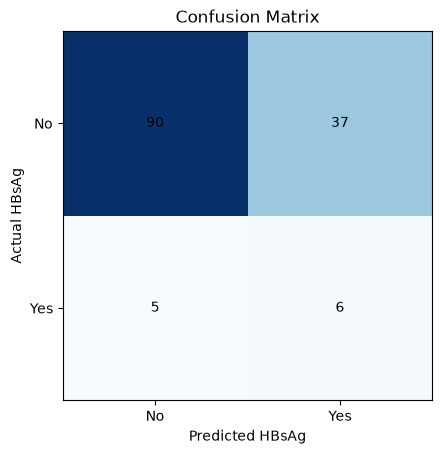

In [50]:
cm = confusion_matrix(y_test, balpred)
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])
plt.xlabel('Predicted HBsAg')
plt.ylabel('Actual HBsAg')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.show()

In [51]:
prob2 = balmod.predict_proba(X_test)[:, 1]

auc1 = roc_auc_score(y_test, prob2)

print("ROC-AUC:", auc1)

ROC-AUC: 0.6879026485325698


#### Visualization of ROC Curve for Balanced Model
Citation: Open AI for Chart Code

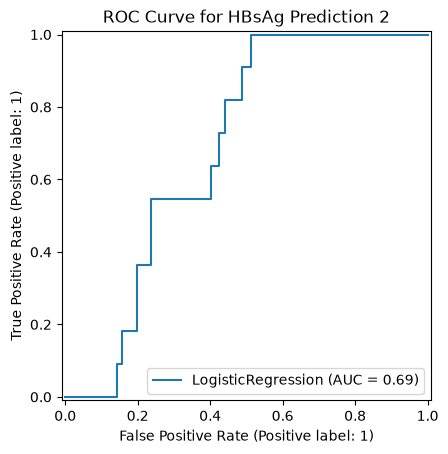

In [52]:
RocCurveDisplay.from_estimator(balmod, X_test, y_test)
plt.title("ROC Curve for HBsAg Prediction 2")
plt.show()

The balanced model achieved 69.6% accuracy and an improved sensitivity of 0.55, correctly identifying 6 of 11 HBsAg-positive patients, compared to none in Model 1. However, the number of false positives increased from 1 to 37,  meaning many negative patients were incorrectly classified as positive. With only 14% precision and a ROC-AUC of 0.687, the model still struggled to reliably distinguish between positive and negative patients.

## Exploring Difference Cutoffs on the Balanced Model

Citation OpenAI + Discussion with professor about playing with cutoffs for the models

Since our dataset is imbalanced, we explored different classification cutoffs ranging from 0.1 to 0.8 using the balanced logistic regression model. The aim was to understand how changing the cutoff affects accuracy, precision, and recall, particularly when identifying HBsAg-positive patients.

In [53]:
cutoffs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

results = []

for cutoff in cutoffs:
    new_pred = (prob2 >= cutoff).astype(int)

    results.append({
        'Cutoff': cutoff,
        'Accuracy': accuracy_score(y_test, new_pred),
        'Precision': precision_score(y_test, new_pred, zero_division=0),
        'Recall': recall_score(y_test, new_pred, zero_division=0)
    })

cutoff_df = pd.DataFrame(results)
cutoff_df.round(3)

,Cutoff,Accuracy,Precision,Recall
0,0.1,0.094,0.081,1.000
1,0.2,0.188,0.089,1.000
2,0.3,0.362,0.111,1.000
3,0.4,0.543,0.129,0.818
4,0.5,0.696,0.140,0.545
5,0.6,0.783,0.087,0.182
6,0.7,0.819,0.000,0.000
7,0.8,0.870,0.000,0.000


The results show that lowering the classification cutoff increases recall but decreases overall accuracy and leads to more false positives.

At a cutoff of 0.3, the model correctly identifies all 11 HBsAg-positive patients (100% recall). However, precision is only 11.1%, meaning most patients predicted positive are actually negative.

At the default cutoff of 0.5, recall decreases to 54.5%, meaning only 6 of the 11 positive patients are correctly identified. Precision increases slightly to 14%.

At higher cutoffs of 0.7 and 0.8, the model fails to identify any positive patients, despite achieving higher overall accuracy.

These findings demonstrate that there is no cutoff that achieves both high precision and high recall. Although lowering the cutoff improves the detection of positive cases, it also increases false positives. Therefore, changing the cutoff does not solve the model's limited ability to distinguish between HBsAg-positive and HBsAg-negative patients.

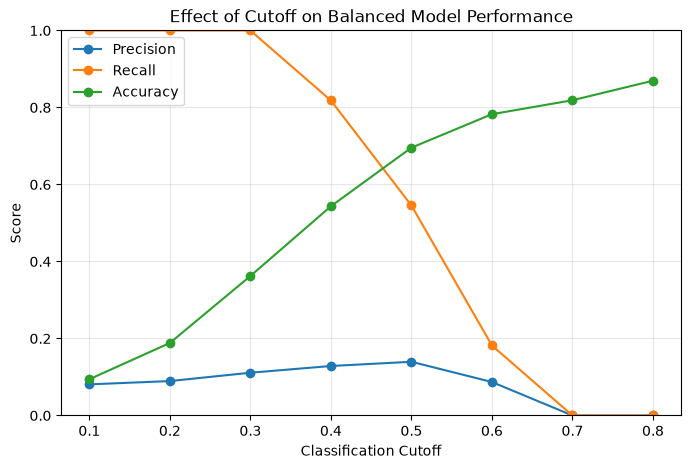

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(cutoff_df['Cutoff'], cutoff_df['Precision'],marker='o', label='Precision')

plt.plot(cutoff_df['Cutoff'], cutoff_df['Recall'], marker='o', label='Recall')

plt.plot(cutoff_df['Cutoff'], cutoff_df['Accuracy'], marker='o', label='Accuracy')

plt.xlabel('Classification Cutoff')
plt.ylabel('Score')
plt.title('Effect of Cutoff on Balanced Model Performance')
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Conclusion

The ROC-AUC of both models (approximately 0.69) suggests the models have a limited capability to distinguish between positive and negative cases, which is especially illustrated in the confusion matrix of the unbalanced model, where it failed to identify HBsAg-positive cases despite its high accuracy. This could be due to the class imbalance in the original cohort, as 75/950 patients were HBsAg-positive. Additionally, incomplete patient records resulted in the exclusion of 262 patients, potentially reducing the number of positive cases in the sample.  

Further research should aim to increase the sample size and prioritise collecting complete and accurately recorded patient records to increase the chances of having a higher proportion of positive HBV/HIV co-infection cases and reduce bias. Additionally, more research could be done to evaluate the associations between demographic and exposure characterisitics to assess the possiblities of building profiles of HIV-postive patients who are more susceptible to contracting HBV. These findings can help establish more targeted screening protocols. 

